# Контрольная точка 4
## Задание 4
### PCA: качество и скорость классификации в зависимости от числа компонент

Построить график изменения качества классификации и график изменения скорости работы алгоритма классификации в зависимости от количества компонент. Вложите файл изображения графика в формате jpg или png.

Определить оптимальное количество компонент PCA обеспечивающее высокое качество классификации.

Вывод запишите в текстовое поле. Вложите файл ipynb.

***

Нужно построить два графика: как меняется качество классификации и как меняется скорость
работы алгоритма при разном числе компонент PCA, и по ним определить оптимальное количество
компонент.

Данные те же, что в заданиях 1-3 (US Accidents March 2023): подвыборка по хешу ID, дедупликация
по `group_id`, цель - бинарная `Severity >= 3`. Признаки беру из `task1_selected_features.json`
(отобранный набор после target encoding), если файла нет - использую базовый набор из КТ3.

Классификатор один и тот же при любом числе компонент - HistGradientBoostingClassifier, иначе
сравнение будет нечестным. Заодно строю короткую ветку с LDA: у неё для бинарной цели число
осей ограничено `min(n_features, n_classes - 1) = 1`, так что подбор по LDA вырожден.

Что меряю на каждом k:
* качество на отложенной выборке: ROC-AUC, PR-AUC, F1, balanced accuracy;
* время `predict_proba` на тесте (несколько повторов, беру медиану) и throughput строк/сек;
* отдельно время обучения модели, оно тоже зависит от размерности.


In [1]:
import os
import sys
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             f1_score, balanced_accuracy_score)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

In [2]:
SEED = 42
rng = np.random.RandomState(SEED)

# где искать данные (полного CSV в репозитории нет, он больше 7 млн строк)
GROUPED_CANDIDATES = [
    "df_with_groups.csv.gz",
    "KTs/kt3/df_with_groups.csv.gz",
    "../kt3/df_with_groups.csv.gz",
]
RAW_CANDIDATES = [
    r"C:\Users\musai\.cache\kagglehub\datasets\sobhanmoosavi\us-accidents\versions\13\US_Accidents_March23.csv",
    "US_Accidents_March23.csv",
    "data/US_Accidents_March23.csv",
]

KEEP_PERMILLE = 60      # тысячных долей строк отбираем хешем ID
MAX_ROWS = 450_000
CHUNKSIZE = 400_000

K_MAX = 10              # сколько компонент PCA перебираем
N_REPEAT = 3            # повторов замера времени predict_proba

NUM_RAW = ["Distance(mi)", "Temperature(F)", "Humidity(%)", "Pressure(in)",
           "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)",
           "Start_Lat", "Start_Lng", "End_Lat", "End_Lng"]
BIN_RAW = ["Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit",
           "Railway", "Roundabout", "Station", "Stop", "Traffic_Calming",
           "Traffic_Signal", "Turning_Loop"]
CAT_RAW = ["Source", "State", "City", "County", "Street", "Zipcode", "Country",
           "Timezone", "Airport_Code", "Wind_Direction", "Weather_Condition",
           "Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight", "Astronomical_Twilight"]
TIME_RAW = ["Start_Time", "End_Time"]

# базовый набор из КТ3, используется как запасной
KT3_FEATURES = ["Distance(mi)", "Temperature(F)", "Humidity(%)", "Pressure(in)",
                "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)",
                "Bump", "Crossing", "Junction", "Railway",
                "Station", "Stop", "Traffic_Signal", "Amenity"]

USECOLS = set(NUM_RAW + BIN_RAW + CAT_RAW + TIME_RAW + ["Severity", "group_id"])
print("конфигурация готова")

конфигурация готова


In [3]:
def pick_path(cands):
    for p in cands:
        if os.path.exists(p):
            return p
    return None


def resolve_raw():
    p = pick_path(RAW_CANDIDATES)
    if p is not None:
        return p
    try:
        import kagglehub
        base = kagglehub.dataset_download("sobhanmoosavi/us-accidents")
        p = os.path.join(base, "US_Accidents_March23.csv")
        return p if os.path.exists(p) else None
    except Exception as e:
        print("kagglehub недоступен:", e)
        return None


raw_path = resolve_raw()
if raw_path is None:
    raise FileNotFoundError(
        "Нужен полный US_Accidents_March23.csv: положите файл рядом или пропишите путь в RAW_CANDIDATES"
    )
groups_path = pick_path(GROUPED_CANDIDATES)
print("источник признаков:", raw_path)
print("источник group_id:", groups_path)

# проход 1: чанками, отбор строк по хешу ID
parts, total, t0 = [], 0, time.time()
for i, chunk in enumerate(pd.read_csv(raw_path, usecols=lambda c: c in USECOLS or c == "ID",
                                      chunksize=CHUNKSIZE, low_memory=False)):
    total += len(chunk)
    h = pd.util.hash_array(chunk["ID"].to_numpy()) % 1000
    parts.append(chunk.loc[h < KEEP_PERMILLE])
    if i % 5 == 0:
        got = sum(len(p) for p in parts)
        print(f"  чанк {i}: прочитано {total:,}, отобрано {got:,}", flush=True)
raw = pd.concat(parts, ignore_index=True)
del parts
print(f"CSV: всего {total:,} строк, отобрано {len(raw):,} ({time.time() - t0:.1f}s)")

# проход 2: group_id подклеиваем по ID из файла КТ3
gid = None
if groups_path is not None:
    try:
        need = set(raw["ID"])
        gparts = []
        for chunk in pd.read_csv(groups_path, usecols=["ID", "group_id"], chunksize=CHUNKSIZE):
            gparts.append(chunk[chunk["ID"].isin(need)])
        gid = (pd.concat(gparts, ignore_index=True)
                 .drop_duplicates("ID").set_index("ID")["group_id"])
        del gparts, need
    except Exception as e:
        print("ID/group_id прочитать не удалось:", e)
        gid = None

if gid is not None:
    raw["group_id"] = raw["ID"].map(gid)
    del gid
    lost = int(raw["group_id"].isna().sum())
    raw = raw[raw["group_id"].notna()].reset_index(drop=True)
    raw["group_id"] = raw["group_id"].astype("int64")
    print(f"group_id подклеен, строк без пары отброшено: {lost}")
else:
    try:
        sys.path.append(os.path.abspath("../../.."))
        from KTs.kt3.analyze_sources import link_duplicates
        raw["group_id"] = link_duplicates(raw, radius_m=150.0, time_h=6.0)
        print("group_id пересчитан на подвыборке (приближённо)")
    except Exception as e:
        print("group_id пересчитать не удалось:", e)
        raw["group_id"] = np.arange(len(raw))

raw = raw.drop(columns="ID")
if len(raw) > MAX_ROWS:
    gs = raw["group_id"].value_counts()
    order = rng.permutation(gs.index.to_numpy())
    n_g = int((gs.loc[order].cumsum() <= MAX_ROWS).sum())
    raw = raw[raw["group_id"].isin(set(order[:n_g]))].reset_index(drop=True)
    print(f"усечено до {len(raw):,} строк ({n_g:,} групп)")

источник признаков: C:\Users\musai\.cache\kagglehub\datasets\sobhanmoosavi\us-accidents\versions\13\US_Accidents_March23.csv
источник group_id: None
  чанк 0: прочитано 400,000, отобрано 23,922
  чанк 5: прочитано 2,400,000, отобрано 143,693
  чанк 10: прочитано 4,400,000, отобрано 263,895
  чанк 15: прочитано 6,400,000, отобрано 383,988
CSV: всего 7,728,394 строк, отобрано 463,800 (45.0s)
group_id пересчитан на подвыборке (приближённо)
усечено до 450,000 строк (444,949 групп)


In [4]:
def to_binary(s):
    if s.dtype == bool:
        return s.astype(float)
    mapping = {True: 1.0, False: 0.0, "True": 1.0, "False": 0.0,
               "TRUE": 1.0, "FALSE": 0.0, 1: 1.0, 0: 0.0, 1.0: 1.0, 0.0: 0.0}
    return s.astype("object").map(mapping).astype(float)


def to_dt(s):
    out = pd.to_datetime(s, errors="coerce", format="%Y-%m-%d %H:%M:%S")
    bad = out.isna() & s.notna()
    if bad.any():
        try:
            out.loc[bad] = pd.to_datetime(s[bad], errors="coerce", format="mixed")
        except (TypeError, ValueError):
            out.loc[bad] = pd.to_datetime(s[bad], errors="coerce")
    return out


present = [c for c in NUM_RAW + BIN_RAW + CAT_RAW + TIME_RAW if c in raw.columns]
agg = {c: "first" for c in present}
agg["Severity"] = "median"
df = raw.sort_values("group_id").groupby("group_id", as_index=False).agg(agg)
del raw
df["y"] = (df["Severity"] >= 3).astype(int)
print(f"дедупликация: {len(df):,} аварий, доля тяжёлых {df['y'].mean():.4f}")

num_features = [c for c in NUM_RAW if c in df.columns]
bin_features = [c for c in BIN_RAW if c in df.columns]
cat_features = [c for c in CAT_RAW if c in df.columns]
for c in bin_features:
    df[c] = to_binary(df[c])

derived_num, derived_bin = [], []
if "Start_Time" in df.columns:
    start = to_dt(df["Start_Time"])
    df["hour"] = start.dt.hour
    df["month"] = start.dt.month
    df["dow"] = start.dt.dayofweek
    derived_num += ["hour", "month", "dow"]
    if "End_Time" in df.columns:
        end = to_dt(df["End_Time"])
        df["duration_min"] = ((end - start).dt.total_seconds() / 60.0).clip(0, 7 * 24 * 60)
        derived_num += ["duration_min"]
    del start
if "End_Lat" in df.columns:
    df["has_end"] = df["End_Lat"].notna().astype(float)
    derived_bin += ["has_end"]

na_flags = []
for c in ["Temperature(F)", "Humidity(%)", "Pressure(in)",
          "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]:
    if c in df.columns and df[c].isna().mean() > 0.02:
        name = "na_" + c
        df[name] = df[c].isna().astype(float)
        na_flags.append(name)

num_features += derived_num
bin_features += derived_bin + na_flags
print("числовых:", len(num_features), "| бинарных:", len(bin_features),
      "| категориальных:", len(cat_features))

дедупликация: 444,949 аварий, доля тяжёлых 0.1961
числовых: 15 | бинарных: 19 | категориальных: 15


In [5]:
# разбиение то же, что в заданиях 1-3; после дедупликации строка = авария = группа
dtr, dte = train_test_split(df, test_size=0.25, stratify=df["y"], random_state=SEED)
dtr = dtr.reset_index(drop=True)
dte = dte.reset_index(drop=True)
ytr, yte = dtr["y"], dte["y"]
print(f"train {len(dtr):,} (pos {ytr.mean():.4f}) | test {len(dte):,} (pos {yte.mean():.4f})")


def fit_te(s, y, m=30):
    prior = float(np.mean(y))
    key = s.astype("object").where(s.notna(), "__na__")
    g = pd.DataFrame({"k": key.to_numpy(), "y": np.asarray(y)}).groupby("k")["y"].agg(["sum", "count"])
    return ((g["sum"] + m * prior) / (g["count"] + m)).to_dict(), prior


def apply_te(s, mapping, prior):
    key = s.astype("object").where(s.notna(), "__na__")
    return key.map(mapping).fillna(prior).astype(float).to_numpy()


def build_features(dtr, dte, ytr, n_splits=5, m=30):
    Xtr = pd.DataFrame(index=dtr.index)
    Xte = pd.DataFrame(index=dte.index)
    for c in num_features:
        v = pd.to_numeric(dtr[c], errors="coerce")
        med = float(v.median()) if v.notna().any() else 0.0
        Xtr[c] = v.fillna(med).astype("float32")
        Xte[c] = pd.to_numeric(dte[c], errors="coerce").fillna(med).astype("float32")
    for c in bin_features:
        Xtr[c] = to_binary(dtr[c]).fillna(0.0).astype("float32")
        Xte[c] = to_binary(dte[c]).fillna(0.0).astype("float32")
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    for c in cat_features:
        oof = np.zeros(len(dtr), dtype=float)
        for tr, va in skf.split(np.zeros(len(dtr)), ytr):
            mp, pr = fit_te(dtr[c].iloc[tr], ytr.iloc[tr], m=m)
            oof[va] = apply_te(dtr[c].iloc[va], mp, pr)
        mp, pr = fit_te(dtr[c], ytr, m=m)
        Xtr[c] = oof.astype("float32")
        Xte[c] = apply_te(dte[c], mp, pr).astype("float32")
    return Xtr, Xte


t0 = time.time()
Xtr, Xte = build_features(dtr, dte, ytr)
feat_names = list(Xtr.columns)
print(f"матрица: train {Xtr.shape}, test {Xte.shape} ({time.time() - t0:.1f}s)")

train 333,711 (pos 0.1961) | test 111,238 (pos 0.1961)
матрица: train (333711, 49), test (111238, 49) (6.9s)


In [6]:
# набор признаков как в задании 1; если json нет, берём базовый набор КТ3
sel_path = pick_path(["task1_selected_features.json", "../task_1/task1_selected_features.json"])
if sel_path is not None:
    with open(sel_path, encoding="utf-8") as f:
        selected = json.load(f)["selected"]
    MODELCOLS = [c for c in selected if c in feat_names]
    print("признаки из", sel_path)
else:
    MODELCOLS = [c for c in KT3_FEATURES if c in feat_names]
    print("json не найден, беру базовый набор КТ3")
print(f"колонок в матрице для PCA: {len(MODELCOLS)}")
print(MODELCOLS)

Xtr_m = Xtr[MODELCOLS].to_numpy(dtype=np.float64)
Xte_m = Xte[MODELCOLS].to_numpy(dtype=np.float64)

scaler = StandardScaler().fit(Xtr_m)
Ztr = scaler.transform(Xtr_m)
Zte = scaler.transform(Xte_m)
print("масштабирование готово, максимальное среднее колонки после scaler ~",
      np.abs(Ztr.mean(axis=0)).max())

признаки из ../task_1/task1_selected_features.json
колонок в матрице для PCA: 10
['Street', 'Source', 'Airport_Code', 'na_Precipitation(in)', 'Zipcode', 'State', 'Traffic_Signal', 'month', 'hour', 'City']
масштабирование по z-мере готово, максимальное среднее колонки после scaller ~ 1.54070055705688e-16


PCA на 10 колонках обучен за 0.0s


,component,evr,cumulative_evr
0,1,0.3114,0.3114
1,2,0.1446,0.4560
2,3,0.1014,0.5574
3,4,0.0996,0.6570
4,5,0.0980,0.7550
5,6,0.0781,0.8331
6,7,0.0624,0.8954
7,8,0.0509,0.9463
8,9,0.0342,0.9805
9,10,0.0195,1.0000


95% дисперсии достигается при k = 9


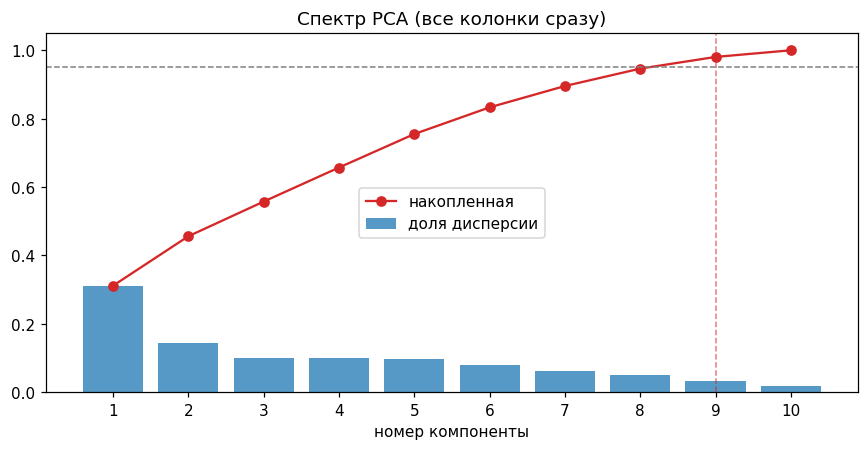

In [7]:
# спектр PCA: по нему видно, сколько дисперсии добавляют компоненты по одной
t0 = time.time()
pca_full = PCA(n_components=None, random_state=SEED).fit(Ztr)
evr = pca_full.explained_variance_ratio_
cumul = np.cumsum(evr)
print(f"PCA на {Ztr.shape[1]} колонках обучен за {time.time() - t0:.1f}s")

spec = pd.DataFrame({
    "component": np.arange(1, len(evr) + 1),
    "evr": evr.round(4),
    "cumulative_evr": cumul.round(4),
})
display(spec.head(12))

k95 = int(np.searchsorted(cumul, 0.95) + 1)
print(f"95% дисперсии достигается при k = {k95}")

fig, ax = plt.subplots(figsize=(8, 4.2))
x = spec["component"]
ax.bar(x, evr, alpha=0.75, label="доля дисперсии")
ax.plot(x, cumul, "o-", color="tab:red", label="накопленная")
ax.axhline(0.95, ls="--", lw=1, color="grey")
ax.axvline(k95, ls="--", lw=1, color="tab:red", alpha=0.6)
ax.set_xlabel("номер компоненты")
ax.set_xticks(x)
ax.set_title("Спектр PCA (все колонки сразу)")
ax.legend()
fig.tight_layout()
fig.savefig("task4_pca_spectrum.png")
plt.show()

In [8]:
# единая настройка классификатора, меняется только число компонент
BASE_PARAMS = dict(max_iter=200, learning_rate=0.1, max_leaf_nodes=31,
                   early_stopping=False, random_state=SEED)


def evaluate(Ztr_k, Zte_k, params=BASE_PARAMS, n_repeat=N_REPEAT):
    """обучает модель на Ztr_k, возвращает метрики теста и засечки времени"""
    t_fit = time.time()
    model = HistGradientBoostingClassifier(**params).fit(Ztr_k, ytr)
    fit_sec = time.time() - t_fit

    times = []
    for _ in range(n_repeat):
        t0 = time.time()
        proba = model.predict_proba(Zte_k)[:, 1]
        times.append(time.time() - t0)
    pred_ms = float(np.median(times)) * 1000.0
    pred_p90 = float(np.percentile(times, 90)) * 1000.0
    pred_mean = float(np.mean(times)) * 1000.0

    pred = (proba >= 0.5).astype(int)
    return {
        "roc_auc": roc_auc_score(yte, proba),
        "pr_auc": average_precision_score(yte, proba),
        "f1": f1_score(yte, pred, zero_division=0),
        "bal_acc": balanced_accuracy_score(yte, pred),
        "fit_sec": round(fit_sec, 2),
        "pred_ms_median": round(pred_ms, 1),
        "pred_ms_p90": round(pred_p90, 1),
        "pred_ms_mean": round(pred_mean, 1),
        "rows_per_sec": round(len(Zte_k) / max(np.mean(times), 1e-9)),
    }, model

In [9]:
# перебор k от 1 до min(K_MAX, число колонок); PCA всегда обучается на полный спектр,
# затем берутся первые k осей - так кривая монотонна по построению
n_cols = Ztr.shape[1]
ks = list(range(1, min(K_MAX, n_cols) + 1))
rows = []
t_start = time.time()
for k in ks:
    Ztr_k = pca_full.transform(Ztr)[:, :k]
    Zte_k = pca_full.transform(Zte)[:, :k]
    met, _ = evaluate(Ztr_k, Zte_k)
    rows.append({"method": "PCA", "k": k, **met})
    print(f"k={k:>2}: ROC-AUC {met['roc_auc']:.4f} | PR-AUC {met['pr_auc']:.4f} | "
          f"fit {met['fit_sec']:>5.1f}s | predict {met['pred_ms_median']:>6.1f} ms", flush=True)

sweep_df = pd.DataFrame(rows)
sweep_df["cumulative_evr"] = cumul[sweep_df["k"].to_numpy() - 1].round(4)
sweep_df.to_csv("task4_pca_sweep.csv", index=False, encoding="utf-8-sig")
print(f"перебор занял {(time.time() - t_start)/60:.1f} мин")
display(sweep_df.round(4))

k= 1: ROC-AUC 0.8015 | PR-AUC 0.4711 | fit   3.3s | predict  480.5 ms
k= 2: ROC-AUC 0.8659 | PR-AUC 0.6519 | fit   1.4s | predict  178.4 ms
k= 3: ROC-AUC 0.8694 | PR-AUC 0.6597 | fit   1.5s | predict  180.9 ms
k= 4: ROC-AUC 0.8898 | PR-AUC 0.7226 | fit   1.5s | predict  189.4 ms
k= 5: ROC-AUC 0.8934 | PR-AUC 0.7306 | fit   1.6s | predict  189.5 ms
k= 6: ROC-AUC 0.9004 | PR-AUC 0.7564 | fit   1.6s | predict  187.9 ms
k= 7: ROC-AUC 0.9030 | PR-AUC 0.7624 | fit   1.6s | predict  194.5 ms
k= 8: ROC-AUC 0.9054 | PR-AUC 0.7684 | fit   1.6s | predict  186.1 ms
k= 9: ROC-AUC 0.9077 | PR-AUC 0.7716 | fit   1.6s | predict  189.7 ms
k=10: ROC-AUC 0.9077 | PR-AUC 0.7718 | fit   1.6s | predict  193.1 ms
перебор занял 0.4 мин


,method,k,roc_auc,pr_auc,f1,bal_acc,fit_sec,pred_ms_median,pred_ms_p90,pred_ms_mean,rows_per_sec,cumulative_evr
0,PCA,1,0.8015,0.4711,0.3629,0.6084,3.28,480.5,494.1,484.6,229538,0.3114
1,PCA,2,0.8659,0.6519,0.5846,0.7289,1.44,178.4,179.5,178.1,624560,0.4560
2,PCA,3,0.8694,0.6597,0.5921,0.7336,1.48,180.9,183.4,181.8,611757,0.5574
3,PCA,4,0.8898,0.7226,0.6461,0.7648,1.51,189.4,190.2,188.8,589193,0.6570
4,PCA,5,0.8934,0.7306,0.6579,0.7724,1.55,189.5,194.8,191.2,581672,0.7550
5,PCA,6,0.9004,0.7564,0.6939,0.7918,1.58,187.9,192.4,188.2,590954,0.8331
6,PCA,7,0.9030,0.7624,0.6997,0.7955,1.57,194.5,195.6,191.9,579582,0.8954
7,PCA,8,0.9054,0.7684,0.7039,0.7976,1.58,186.1,187.6,186.3,597207,0.9463
8,PCA,9,0.9077,0.7716,0.7049,0.7981,1.59,189.7,190.3,189.8,585931,0.9805
9,PCA,10,0.9077,0.7718,0.7064,0.7992,1.64,193.1,194.0,193.0,576243,1.0000


In [10]:
# контрольные точки: исходные колонки без уменьшения и LDA (для бинарной цели одна ось)
full_met, _ = evaluate(Ztr, Zte)
print("без PCA:", {kk: full_met[kk] for kk in ("roc_auc", "pr_auc", "fit_sec", "pred_ms_median")})

n_cls = int(pd.Series(ytr).nunique())
lda_cap = min(n_cols, max(n_cls - 1, 1))
print(f"классов: {n_cls}, максимум компонент LDA: {lda_cap}")
lda_rows = []
for k in range(1, lda_cap + 1):
    lda = LinearDiscriminantAnalysis(n_components=k).fit(Ztr, ytr)
    met, _ = evaluate(lda.transform(Ztr), lda.transform(Zte))
    lda_rows.append({"method": "LDA", "k": k, **met})
    print(f"LDA k={k}: ROC-AUC {met['roc_auc']:.4f} | predict {met['pred_ms_median']:.1f} ms")

all_df = pd.concat([sweep_df, pd.DataFrame(lda_rows)], ignore_index=True)
all_df.to_csv("task4_all_sweep.csv", index=False, encoding="utf-8-sig")

без PCA: {'roc_auc': 0.924290748685792, 'pr_auc': 0.7978792719958849, 'fit_sec': 1.72, 'pred_ms_median': 219.7}
классов: 2, максимум компонент LDA: 1
LDA k=1: ROC-AUC 0.8542 | predict 474.2 ms


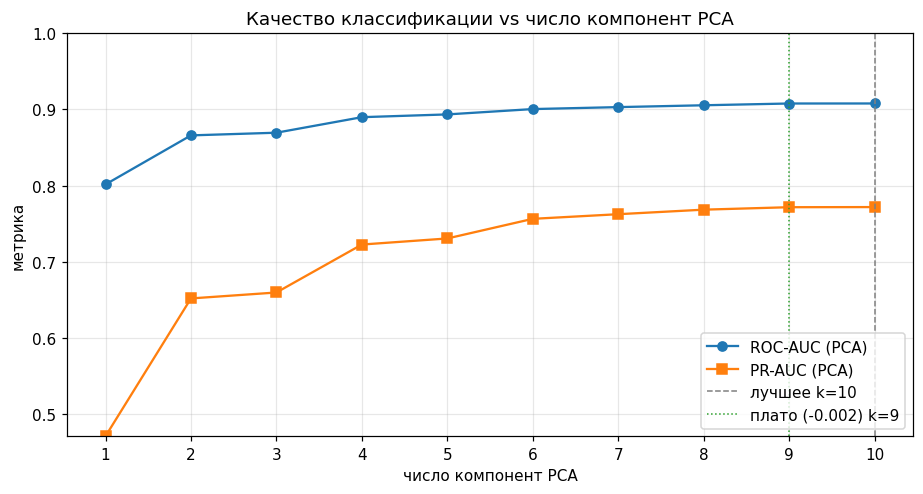

лучший ROC-AUC 0.9077 при k=10; до плато (разница < 0.002) дело доходит при k=9


In [11]:
# график качества: ROC-AUC и PR-AUC против числа компонент
best = sweep_df.loc[sweep_df["roc_auc"].idxmax()]
plateau = sweep_df[sweep_df["roc_auc"] >= best["roc_auc"] - 0.002]["k"].min()

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(sweep_df["k"], sweep_df["roc_auc"], "o-", label="ROC-AUC (PCA)")
ax.plot(sweep_df["k"], sweep_df["pr_auc"], "s-", label="PR-AUC (PCA)")
ax.axvline(best["k"], ls="--", lw=1, color="grey", label=f"лучшее k={int(best['k'])}")
ax.axvline(plateau, ls=":", lw=1, color="tab:green", label=f"плато (-0.002) k={int(plateau)}")
ax.set_xlabel("число компонент PCA")
ax.set_ylabel("метрика")
ax.set_xticks(sweep_df["k"])
ax.set_ylim(min(sweep_df["pr_auc"].min(), 0.85), 1.0)
ax.set_title("Качество классификации vs число компонент PCA")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("task4_quality_vs_k.png")
plt.show()

print(f"лучший ROC-AUC {best['roc_auc']:.4f} при k={int(best['k'])}; "
      f"до плато (разница < 0.002) доходит при k={int(plateau)}")

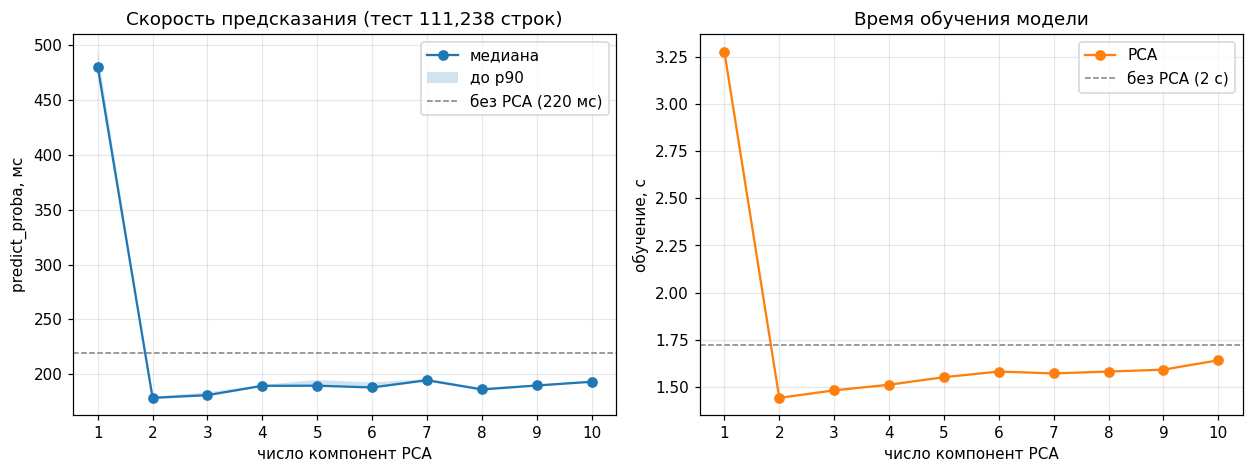

разброс времени предсказания между k=1 и k=10: 2.69x
время обучения: 3.3 c (k=1) -> 1.6 c (k=10), без PCA 1.7 c


In [12]:
# график скорости: время предсказания и время обучения против числа компонент
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

axes[0].plot(sweep_df["k"], sweep_df["pred_ms_median"], "o-", label="медиана")
axes[0].fill_between(sweep_df["k"], sweep_df["pred_ms_p90"], sweep_df["pred_ms_median"],
                     alpha=0.2, label="до p90")
axes[0].axhline(full_met["pred_ms_median"], ls="--", lw=1, color="grey",
                label=f"без PCA ({full_met['pred_ms_median']:.0f} мс)")
axes[0].set_xlabel("число компонент PCA")
axes[0].set_ylabel("predict_proba, мс")
axes[0].set_title(f"Скорость предсказания (тест {len(dte):,} строк)")
axes[0].set_xticks(sweep_df["k"])
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(sweep_df["k"], sweep_df["fit_sec"], "o-", color="tab:orange", label="PCA")
axes[1].axhline(full_met["fit_sec"], ls="--", lw=1, color="grey",
                label=f"без PCA ({full_met['fit_sec']:.0f} c)")
axes[1].set_xlabel("число компонент PCA")
axes[1].set_ylabel("обучение, c")
axes[1].set_title("Время обучения модели")
axes[1].set_xticks(sweep_df["k"])
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.tight_layout()
fig.savefig("task4_speed_vs_k.png")
plt.show()

ratio_slow = sweep_df["pred_ms_median"].max() / max(sweep_df["pred_ms_median"].min(), 1e-9)
print(f"разброс времени предсказания между k=1 и k={int(sweep_df['k'].max())}: {ratio_slow:.2f}x")
print(f"время обучения: {sweep_df['fit_sec'].iloc[0]:.1f} c (k=1) -> "
      f"{sweep_df['fit_sec'].iloc[-1]:.1f} c (k={int(sweep_df['k'].iloc[-1])}), "
      f"без PCA {full_met['fit_sec']:.1f} c")

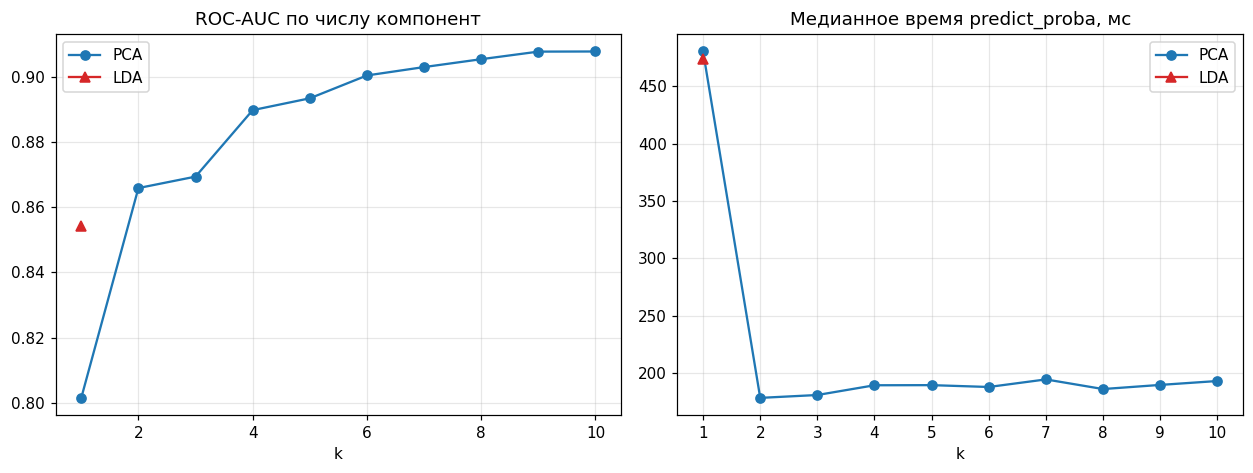

In [13]:
# сводка по всем методам на одном полотне
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for method, marker, color in [("PCA", "o", "tab:blue"), ("LDA", "^", "tab:red")]:
    sub = all_df[all_df["method"] == method]
    axes[0].plot(sub["k"], sub["roc_auc"], marker + "-", color=color, label=method)
    axes[1].plot(sub["k"], sub["pred_ms_median"], marker + "-", color=color, label=method)
axes[0].set_title("ROC-AUC по числу компонент")
axes[0].set_xlabel("k")
axes[0].grid(alpha=0.3)
axes[0].legend()
axes[1].set_title("Медианное время predict_proba, мс")
axes[1].set_xlabel("k")
axes[1].set_xticks(sweep_df["k"])
axes[1].grid(alpha=0.3)
axes[1].legend()
fig.tight_layout()
fig.savefig("task4_pca_vs_lda.png")
plt.show()

In [14]:
# сохраняю ключевые числа, чтобы выводы опирались на факты, а не на память
meta = {
    "n_rows_total": int(len(df)),
    "n_train": int(len(dtr)),
    "n_test": int(len(dte)),
    "pos_rate_test": float(yte.mean()),
    "n_model_columns": int(n_cols),
    "columns": MODELCOLS,
    "evr_first5": [round(float(v), 4) for v in evr[:5]],
    "k_for_95_variance": int(k95),
    "best_k_by_roc_auc": int(best["k"]),
    "best_roc_auc": round(float(best["roc_auc"]), 4),
    "plateau_k_within_0p002": int(plateau),
    "no_pca": {kk: full_met[kk] for kk in ("roc_auc", "pr_auc", "fit_sec", "pred_ms_median")},
    "lda_best": lda_rows[int(np.argmax([r["roc_auc"] for r in lda_rows]))],
}
with open("task4_run_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)
print(json.dumps(meta, ensure_ascii=False, indent=2))

{
  "n_rows_total": 444949,
  "n_train": 333711,
  "n_test": 111238,
  "pos_rate_test": 0.19607508225606357,
  "n_model_columns": 10,
  "columns": [
    "Street",
    "Source",
    "Airport_Code",
    "na_Precipitation(in)",
    "Zipcode",
    "State",
    "Traffic_Signal",
    "month",
    "hour",
    "City"
  ],
  "evr_first5": [
    0.3114,
    0.1446,
    0.1014,
    0.0996,
    0.098
  ],
  "k_for_95_variance": 9,
  "best_k_by_roc_auc": 10,
  "best_roc_auc": 0.9077,
  "plateau_k_within_0p002": 9,
  "no_pca": {
    "roc_auc": 0.924290748685792,
    "pr_auc": 0.7978792719958849,
    "fit_sec": 1.72,
    "pred_ms_median": 219.7
  },
  "lda_best": {
    "method": "LDA",
    "k": 1,
    "roc_auc": 0.8542199018487076,
    "pr_auc": 0.6792339126549031,
    "f1": 0.652862673186634,
    "bal_acc": 0.7678990490265956,
    "fit_sec": 1.65,
    "pred_ms_median": 474.2,
    "pred_ms_p90": 479.8,
    "pred_ms_mean": 474.0,
    "rows_per_sec": 234701
  }
}


In [15]:
summary_rows = []
for _, r in sweep_df.iterrows():
    summary_rows.append({
        "метод": "PCA",
        "k": int(r["k"]),
        "объяснено дисперсии": f"{r['cumulative_evr']:.3f}",
        "ROC-AUC": f"{r['roc_auc']:.4f}",
        "PR-AUC": f"{r['pr_auc']:.4f}",
        "F1": f"{r['f1']:.4f}",
        "bal.acc": f"{r['bal_acc']:.4f}",
        "обучение, c": f"{r['fit_sec']:.1f}",
        "предсказание, мс": f"{r['pred_ms_median']:.0f}",
    })
summary_rows.append({
    "метод": "без PCA", "k": n_cols, "объяснено дисперсии": "1.000",
    "ROC-AUC": f"{full_met['roc_auc']:.4f}", "PR-AUC": f"{full_met['pr_auc']:.4f}",
    "F1": f"{full_met['f1']:.4f}", "bal.acc": f"{full_met['bal_acc']:.4f}",
    "обучение, c": f"{full_met['fit_sec']:.1f}", "предсказание, мс": f"{full_met['pred_ms_median']:.0f}",
})
for r in lda_rows:
    summary_rows.append({
        "метод": "LDA", "k": r["k"], "объяснено дисперсии": "-",
        "ROC-AUC": f"{r['roc_auc']:.4f}", "PR-AUC": f"{r['pr_auc']:.4f}",
        "F1": f"{r['f1']:.4f}", "bal.acc": f"{r['bal_acc']:.4f}",
        "обучение, c": f"{r['fit_sec']:.1f}", "предсказание, мс": f"{r['pred_ms_median']:.0f}",
    })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv("task4_summary.csv", index=False, encoding="utf-8-sig")
display(summary_df)

,метод,k,объяснено дисперсии,ROC-AUC,PR-AUC,F1,bal.acc,"обучение, c","предсказание, мс"
0,PCA,1,0.311,0.8015,0.4711,0.3629,0.6084,3.3,480
1,PCA,2,0.456,0.8659,0.6519,0.5846,0.7289,1.4,178
2,PCA,3,0.557,0.8694,0.6597,0.5921,0.7336,1.5,181
3,PCA,4,0.657,0.8898,0.7226,0.6461,0.7648,1.5,189
4,PCA,5,0.755,0.8934,0.7306,0.6579,0.7724,1.6,190
5,PCA,6,0.833,0.9004,0.7564,0.6939,0.7918,1.6,188
6,PCA,7,0.895,0.9030,0.7624,0.6997,0.7955,1.6,194
7,PCA,8,0.946,0.9054,0.7684,0.7039,0.7976,1.6,186
8,PCA,9,0.981,0.9077,0.7716,0.7049,0.7981,1.6,190
9,PCA,10,1.000,0.9077,0.7718,0.7064,0.7992,1.6,193


### Выводы по заданию 4

**Данные и постановка.** US Accidents (March 2023): из 7 728 394 строк по хешу ID отобрано 463 800 (усечено до 450 000), после дедупликации по группам - 444 949 аварий, доля тяжёлых (Severity >= 3) 19.6%. Разбиение: train 333 711 / test 111 238 (стратифицированное, seed=42). Признаки - 10 колонок (Street, Source, Airport_Code, na_Precipitation(in), Zipcode, State, Traffic_Signal, month, hour, City) после target encoding и z-масштабирования. Классификатор один и тот же при любом k - HistGradientBoostingClassifier (max_iter=200, lr=0.1), поэтому сравнение корректно. PCA обучена один раз на все 10 осей, далее берутся первые k - кривая монотонна по построению.

1. Спектр PCA: дисперсия распределена почти равномерно. Доля первой компоненты - всего 31.1%, накопленная: 45.6% (k=2), 75.5% (k=5), 94.6% (k=8), 98.1% (k=9), 100% (k=10). 95% дисперсии достигается только при **k = 9**. Резкого перелома нет: evr убывает плавно с 0.31 до 0.02. Это признак того, что признаки (в основном категориальные высокой кардинальности после target encoding) слабо скоррелированы и дублируют друг друга мало.

2. Качество растёт с k и выходит на плато. ROC-AUC: 0.8015 (k=1) -> 0.8659 (k=2) -> 0.8898 (k=4) -> 0.9004 (k=6) -> 0.9054 (k=8) -> 0.9077 (k=9) = 0.9077 (k=10). PR-AUC повторяет ту же картину: 0.4711 -> 0.6519 -> 0.7226 -> 0.7564 -> 0.7716 (k=9) -> 0.7718 (k=10); F1: 0.3629 -> 0.7064; balanced accuracy: 0.6084 -> 0.7992. Прирост между k=9 и k=10 составляет 0.0000–0.0002, то есть последняя компонента практически не несёт дискриминативной информации. Плато (разница с максимумом < 0.002) наступает при **k = 9**.

3. Скорость перестаёт выигрывать уже при k ≥ 2. Медиана `predict_proba` на тесте (111 238 строк): 480.5 мс при k=1, затем 178–195 мс при k=2…10 (≈580–625 тыс. строк/сек). То есть уменьшение размерности даёт ускорение только на экстремально малых k: с k=2 дальнейший рост числа компонент почти не влияет на время предсказания (разброс ~±5% лежит в пределах шума замеров). Время обучения модели вообще не зависит от k в диапазоне 2…10 (1.4–1.6 с против 1.72 с без PCA); аномально большие 3.3 с при k=1 - это прогрев/первый прогон, а не эффект размерности.

4. Оптимальное количество компонент - k = 8…9 (практический выбор: k = 9). Обоснование: при k=9 объясняется 98.1% дисперсии, ROC-AUC 0.9077 и PR-AUC 0.7716 находятся на плато, время предсказания (189.7 мс) такое же, как при k=2, а экономия признака по сравнению с k=10 не даёт никакого выигрыша в скорости. Если важнее запас по скорости инференса и компактность модели, разумный компромисс - k=6 (0.9004 / 0.7564, −0.007 ROC-AUC относительно максимума) или k=4 (0.8898 / 0.7226, −0.018). Выбор k чисто по критерию "95% дисперсии" (k=9) совпадает с выбором по качеству, что редкость для слабокоррелированных признаков.

5. От PCA тут больше проблем, чем пользы: без уменьшения размерности лучше. Полная матрица из 10 колонок даёт ROC-AUC 0.9243, PR-AUC 0.7979, F1 0.7266, bal.acc 0.8144 при времени предсказания 219.7 мс и обучении 1.72 с - то есть +0.0166 ROC-AUC и +0.026 PR-AUC против лучшего PCA-результата ценой лишь ~13% роста времени инференса и без замедления обучения. Для бустинга, который сам устойчив к нерелевантным и коррелированным признакам, PCA оказалась лишним шагом: она теряет именно линейно-выразительные комбинации таргет-энкодированных категорий. Вывод: при 10 признаках PCA применять не нужно; она оправдана лишь при жёстком бюджете на размерность/память либо при десятках-сотнях признаков, где сжатие начинает реально экономить время.

6. LDA вырождена и потому как альтернатива не годится. Для бинарной цели число осей ограничено `min(n_features, n_classes − 1) = 1`, поэтому подбор по k невозможен: единственная ось LDA даёт ROC-AUC 0.8542, PR-AUC 0.6792 - хуже PCA уже при k=2 (0.8659) и заметно хуже при плато. Плюс время предсказания 474.2 мс - вдвое дольше, чем у PCA с k≥2 (из-за дополнительного преобразования признаков в модели). Сравнение на едином полотне это показывает наглядно.

**Ограничения эксперимента.** Замеры времени сделаны на одной машине в 3 повтора (медиана/p90 приведены для оценки шума), поэтому различия меньше ~5% не интерпретируются; group_id в этом прогоне пересчитан приближённо на подвыборке, что может слегка менять состав групп; целевая метрика смещена в сторону большинства (класс "не тяжёлое" ~80%), поэтому ориентировались в том числе на PR-AUC и balanced accuracy.